In [1]:
################### Regenerate the maps of 1993 and 1999 with issues using only the points 
################### with the same class with the nearest year ########

from datetime import datetime, timedelta
import os
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import requests
import sys
import geopandas as gpd
import pandas as pd
from shapely.geometry import MultiPoint
from shapely.geometry import Point
import fiona
import contextily as ctx
from datetime import datetime
from sklearn.ensemble import RandomForestClassifier
import simplekml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pyproj import Proj, transform
import ast
from pyproj import Transformer
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.warp import calculate_default_transform, reproject
from rasterio.enums import Resampling

from scipy.ndimage import binary_fill_holes
from scipy.ndimage import convolve
from scipy.ndimage import distance_transform_edt
from affine import Affine
from scipy.spatial import KDTree
from rasterio.mask import mask
from rasterio.features import shapes
from shapely.geometry import shape
from simplekml import Kml
from osgeo import gdal

In [2]:
def count_non_nan_values(array):
        """Counts non-NaN values in an array while ignoring non-numeric elements."""
        # Filter to keep only numeric data (e.g., ints and floats)
        numeric_values = [x for x in array if isinstance(x, (int, float))] 
        # Convert to NumPy array and count non-NaN values
        return np.sum(~np.isnan(np.array(numeric_values, dtype=float)))
    
def data_prep(path, file, path1, file1, cutoff=0, direction=0, cutlon=0, sensor = 1):
    ####### filter the data with 015042 index ######
    df = pd.read_csv(path + file)
    df['ID'] = range(0, len(df))  # Generates IDs starting from 1
    
    if sensor == 0:
        training_data = df[['lat', 'lon', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'ndmi', 'ndvi', 'savi', 'descriptio']].to_numpy()
    else:
        training_data = df[['lat', 'lon', 'SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B7', 'ndmi', 'ndvi', 'savi', 'descriptio']].to_numpy()
    
    predictor = []
    target = []
    coord = []
    # Loop through each (1585, 10) array in training_data
    print('training data is:')
    #print(training_data)
    print(training_data.shape)
    #for array in training_data:
        # Get rows where the target is not 'TZ'
    mask = training_data[:, 11] != 'MZ'
    
    predictor.append(training_data[mask, 2:11])  # First 9 columns
    target.append(training_data[mask, 11])       # Target column
    coord.append(training_data[mask, :2])
    
    # Convert to NumPy arrays if desired
    predictor = np.array(predictor)
    target = np.array(target)
    coord = np.array(coord)
    
    X = predictor.reshape(-1, 9)  # Shape: (5 * 1585, 9)
    y = target.reshape(-1)        # Shape: (5 * 1585,)
    coord = coord.reshape(-1, 2)
    ### cleanse the data by removing nan ####
    valid_indices = []

    # Loop through each row and check for NaN in the first column
    for i in range(X.shape[0]):
        if not np.isnan(X[i, 0]):
            valid_indices.append(i)
    
    # Create new X and y with only valid rows
    X = X[valid_indices]
    y = y[valid_indices]
    coord = coord[valid_indices]

    print('the size of dataset is:')
    print(X.shape[0])

    if cutoff:
        if direction > 0: ### keep the eastern side
            masklon = coord[:, 1] > cutlon
        else:
            masklon = coord[:, 1] <= cutlon
    
        X = X[masklon]
        y = y[masklon]
        coord = coord[masklon]
    
        print('the size of lon filtered dataset is:')
        print(X.shape[0])
        #print(X)
    
    return X, y, coord

In [20]:
def model_train_test(X, y):
    # Initialize the RandomForestClassifier
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    
    # Fit the model to the reshaped data
    model.fit(X, y)
    
    # After training, the model can be used for predictions or evaluation
    y_pred = model.predict(X)
    
    # Calculate accuracy by comparing the predictions with the true labels (y)
    accuracy = model.score(X, y)
    
    print(f"Training and testing using the whole dataset, accuracy is: {accuracy * 100:.2f}%")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_train, y_train)
    
    # Optionally, evaluate the model on the test set
    score = model.score(X_test, y_test)
    print(f"Testing using 20% of the whole dataset, accuracy is: {score*100:.2f}%")
    
    y_pred = model.predict(X_test)

    print("the number of elements for the prediction:")
    print(y_pred.shape[0])
    cm = confusion_matrix(y_test, y_pred, labels=['VZ', 'TZ', 'WZ'])
    
    # Plot the confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['VZ', 'TZ', 'WZ'])
    disp.plot(cmap='Blues', values_format='.0f')
    
    return accuracy

In [23]:
def extract_coordinates(row):
    try:
        # Parse the JSON-like string to a dictionary
        data = ast.literal_eval(row)
        coordinates = data['coordinates']
        lon = round(coordinates[0], 10)
        lat = round(coordinates[1], 10)
        return coordinates[0], coordinates[1]  # lon, lat
    except (ValueError, KeyError):
        return None, None  # Handle parsing errors gracefully

In [27]:
X_1999, y_1999, coord_1999 = data_prep('/Users/bz294/Documents/WhiteZone/Points/KML/1999/', 'median.csv', 0, 0, 0, 1) ## mixing 2022 Mar and 2023 Feb
X_2003, y_2003, coord_2003 = data_prep('/Users/bz294/Documents/WhiteZone/Points/KML/2003/', 'median.csv', 0, 0, 0, 1) ## mixing 2022 Mar and 2023 Feb

training data is:
(1577, 12)
the size of dataset is:
1444
training data is:
(1581, 12)
the size of dataset is:
1448


In [28]:
matching_indices = []
for idx_1999, (y_val_1999, coord_val_1999) in enumerate(zip(y_1999, coord_1999)):
    for idx_2003, (y_val_2003, coord_val_2003) in enumerate(zip(y_2003, coord_2003)):
        # Check if both y and coord match
        if y_val_1999 == y_val_2003 and np.all(coord_val_1999 == coord_val_2003):
            matching_indices.append((idx_1999, idx_2003))

# Convert matching indices to a NumPy array for convenience
matching_indices = np.array(matching_indices)

In [29]:
# Extract the matching indices for 1994
matching_indices_1999 = matching_indices[:, 0]

# Get the subset of y_1994 and coord_1994 using the matching indices
subset_y_1999 = y_1999[matching_indices_1999]
subset_coord_1999 = coord_1999[matching_indices_1999]
subset_X_1999 = X_1999[matching_indices_1999]

y_1999 = subset_y_1999
X_1999 = subset_X_1999
coord_1999 = subset_coord_1999

Training and testing using the whole dataset, accuracy is: 100.00%
Testing using 20% of the whole dataset, accuracy is: 84.53%
the number of elements for the prediction:
265


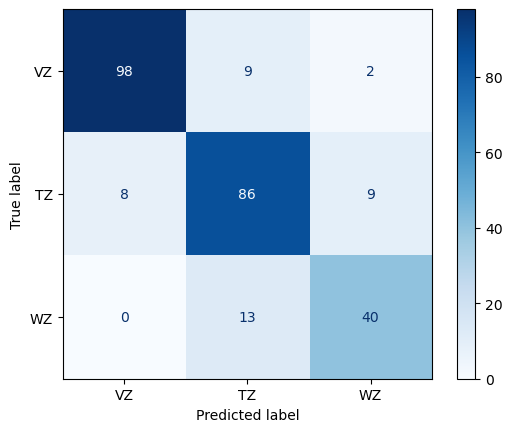

In [30]:
accuracy = model_train_test(X_1999, y_1999)

In [32]:
######### Regional Prediction ###################################
path = "/Users/bz294/Documents/WhiteZone/Points/KML/1999/"
file = "MedianCompositeValues.csv"
region_df = pd.read_csv(path + file)

In [33]:
############ data prep #############

region_df['lon'], region_df['lat'] = zip(*region_df['.geo'].apply(extract_coordinates))
coordinates = region_df[['lon', 'lat']].to_numpy()
feature = region_df.iloc[:, 1:12].drop(region_df.columns[[7, 10]], axis=1).to_numpy()

rows_with_nan = np.any(np.isnan(feature), axis=1)

# Get indices of rows with NaN
indices_with_nan = np.where(rows_with_nan)[0]
print("indices with nan are:")
print(indices_with_nan)

feature_cleaned = np.delete(feature, indices_with_nan, axis=0)
coordinates_cleaned = np.delete(coordinates, indices_with_nan, axis=0)

transformer = Transformer.from_crs("EPSG:4326", "EPSG:32617", always_xy=True)

# Transform the coordinates
coord_utm = np.array([
    transformer.transform(lon, lat) for lon, lat in coordinates_cleaned
])

indices with nan are:
[]


In [34]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
    
# Fit the model to the reshaped data
model.fit(X_1999, y_1999)

# After training, the model can be used for predictions or evaluation
y_region = model.predict(feature_cleaned)

In [35]:
############ Output the shapefile ##############
filename = 'output_points_1999.shp'
geometry = [Point(xy) for xy in coord_utm]

# Create a GeoDataFrame
gdf = gpd.GeoDataFrame({'y_region': y_region}, geometry=geometry)

# Set the CRS to UTM 17N (EPSG:32617)
gdf.set_crs('EPSG:32617', inplace=True)

# Save to a shapefile
output_shapefile = filename  # Define your output shapefile path
gdf.to_file(output_shapefile)

print(f'Shapefile saved to: {output_shapefile}')

Shapefile saved to: output_points_1999.shp
